# Generate plots

In [32]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt

In [33]:
import numpy as np

def per_genotype_double_plot(model1_data, model2_data, metric, title, colours=["#adcbca","#517b7d"], labels=["Fused", "Model 2.5"]):

    model1_geno = model1_data[~model1_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
    model2_geno = model2_data[~model2_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")

    INSTANCE_MODEL1_COLOR = colours[0]
    INSTANCE_MODEL2_COLOR = colours[1]


    merged_instance = model1_geno[[metric]].join(
        model2_geno[[metric]], lsuffix="_model1", rsuffix="_model2"
    )
    merged_instance = merged_instance.sort_values(f"{metric}_model2", ascending=True)

    # --- Lock in this genotype order for reuse ---
    genotype_order = merged_instance.index.tolist()

    x = np.arange(len(merged_instance))
    width = 0.4

    plt.figure(figsize=(12, 7))
    bars1 = plt.bar(x - width/2, merged_instance[f"{metric}_model1"], width=width,
                    color=INSTANCE_MODEL1_COLOR, label=labels[0])
    bars2 = plt.bar(x + width/2, merged_instance[f"{metric}_model2"], width=width,
                    color=INSTANCE_MODEL2_COLOR, label=labels[1])

    plt.bar_label(bars1, fmt="%.2f", fontsize=8, padding=2)
    plt.bar_label(bars2, fmt="%.2f", fontsize=8, padding=2)

    plt.axhline(y=0.7, color="red", linestyle="--", linewidth=1, label="F1 = 0.7 threshold")


    plt.xticks(x, genotype_order, rotation=45, ha="right")
    plt.ylabel(metric)
    plt.title(f"{metric} {title}")
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()
    plt.show()



In [34]:
import numpy as np
import matplotlib.pyplot as plt

def per_genotype_diff_plot(model1_data, model2_data, metric, title, labels=["Fused", "Model 2.5"]):

    model1_geno = model1_data[~model1_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
    model2_geno = model2_data[~model2_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")

    merged_instance = model1_geno[[metric]].join(
        model2_geno[[metric]], lsuffix="_model1", rsuffix="_model2"
    )

    # compute the difference: model1 - model2 (positive = model1 improved)
    merged_instance["diff"] = merged_instance[f"{metric}_model1"] - merged_instance[f"{metric}_model2"]

    merged_instance = merged_instance.sort_values("diff", ascending=False)

    genotype_order = merged_instance.index.tolist()

    x = np.arange(len(merged_instance))

    # color by sign -- green where model2 improved, red where it got worse
    bar_colours = ["#4C9A4C" if v >= 0 else "#C0524F" for v in merged_instance["diff"]]

    plt.figure(figsize=(12, 7))
    bars = plt.bar(x, merged_instance["diff"], color=bar_colours, width=0.6)

    plt.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)

    plt.axhline(y=0, color="black", linewidth=1)  # zero line for reference, not a threshold

    plt.xticks(x, genotype_order, rotation=45, ha="right")
    plt.ylabel(f"Δ {metric} ({labels[1]} − {labels[0]})")
    plt.title(f"{metric} Difference {title}")
    plt.tight_layout()
    plt.show()

In [35]:
folder = "csv_data_for_analysis"

classic_100_no_tangled = f"{folder}/classic_100%_no_tangles.csv"
model_100_no_tangled = f"{folder}/model_100%_no_tangles.csv"
fusion_100_no_tangled = f"{folder}/fusion_100%_no_tangles.csv"

classic_100_no_tangled_data = pd.read_csv(classic_100_no_tangled)
model_100_no_tangled_data = pd.read_csv(model_100_no_tangled)
fusion_100_no_tangled_data = pd.read_csv(fusion_100_no_tangled)

In [36]:


def overall_plot(metric, classic, model, fused, title):
    pipelines = ["classic", "model2.5", "fused"]
    instance_vals = [
        classic[metric],
        model[metric],
        fused[metric],
    ]


    colors = ["#373b3e", "#bec8d1", "#86cecb"]  # coral -> plum gradient

    plt.figure(figsize=(8, 6))
    bars = plt.bar(pipelines, instance_vals, color=colors, width=0.6)

    for bar, val in zip(bars, instance_vals):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.4f}", ha="center", fontsize=11)

    plt.ylabel(metric)
    plt.title(f"{metric} {title}")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

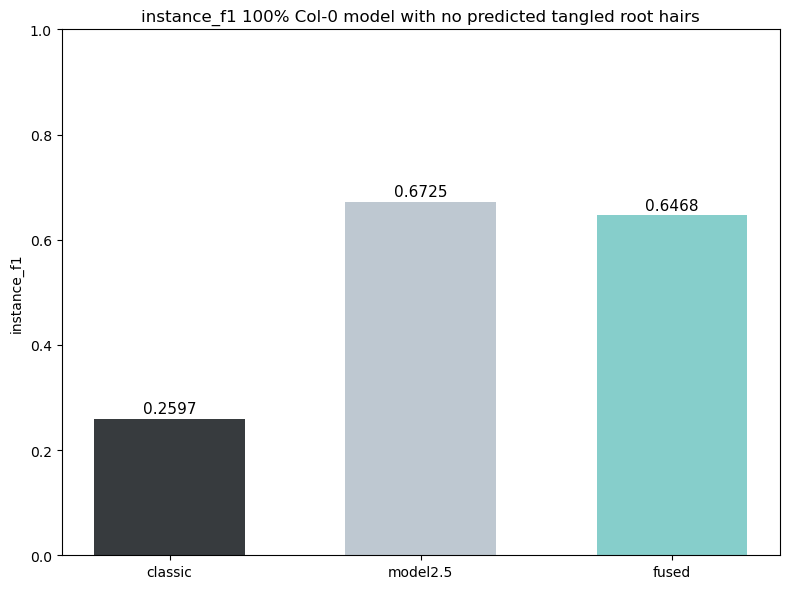

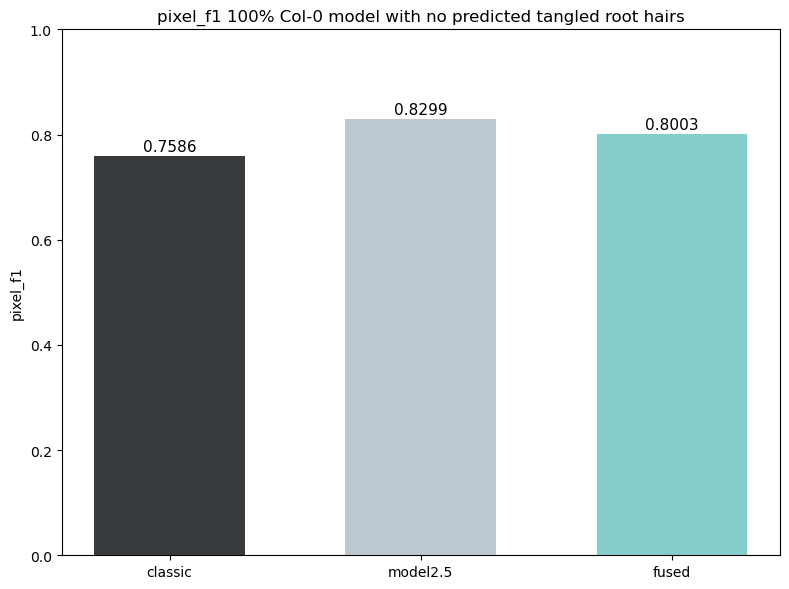

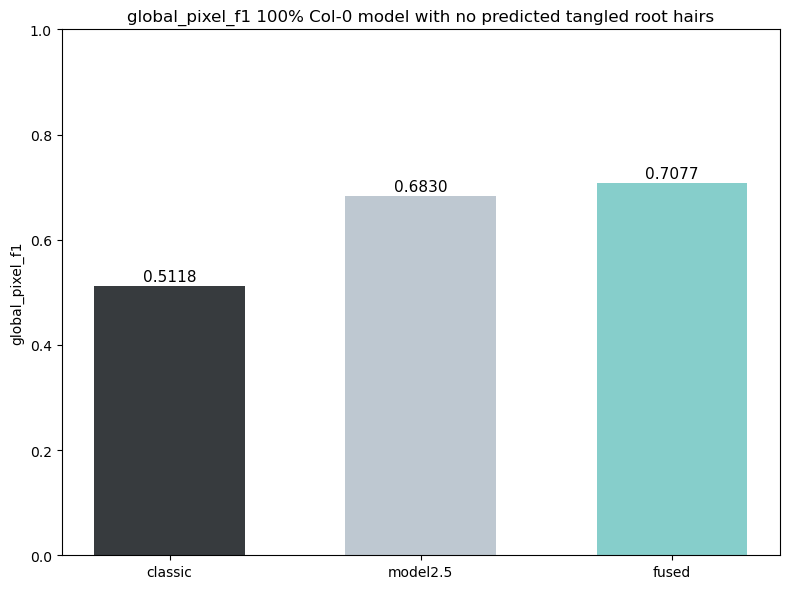

In [37]:
title = "100% Col-0 model with no predicted tangled root hairs"

# Pull TOTAL row from each
classic = classic_100_no_tangled_data[classic_100_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
model = model_100_no_tangled_data[model_100_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
fused = fusion_100_no_tangled_data[fusion_100_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]



overall_plot("instance_f1", classic, model, fused, title)
overall_plot("pixel_f1", classic, model, fused, title)
overall_plot("global_pixel_f1", classic, model, fused, title)


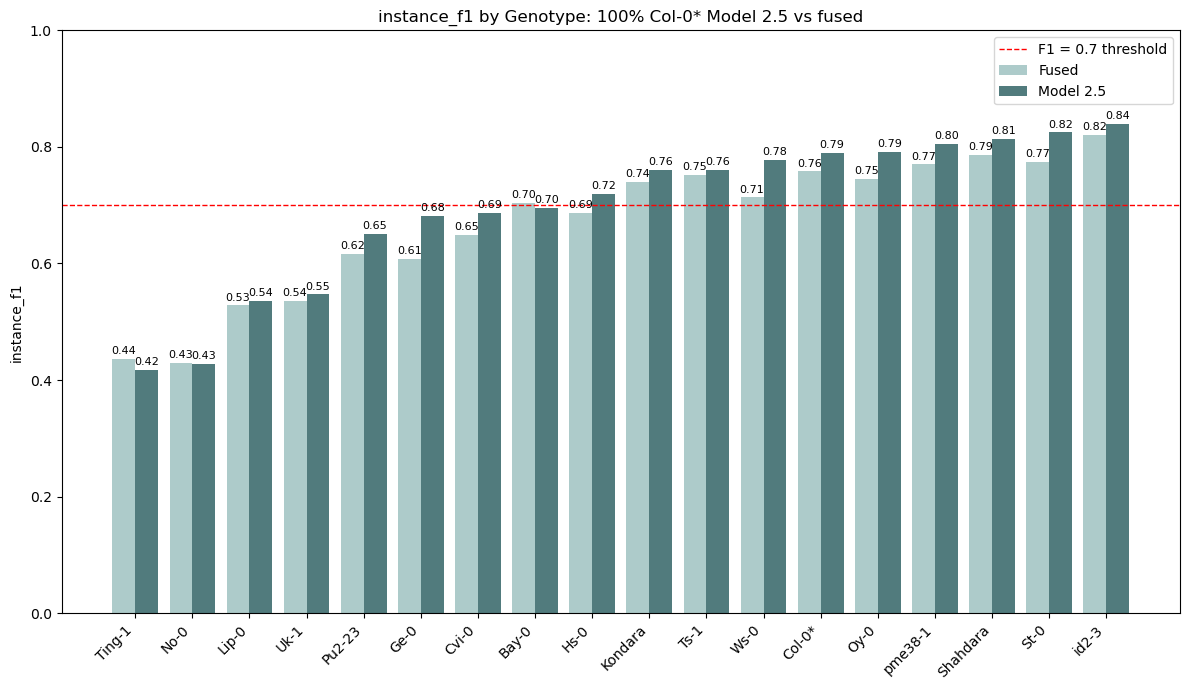

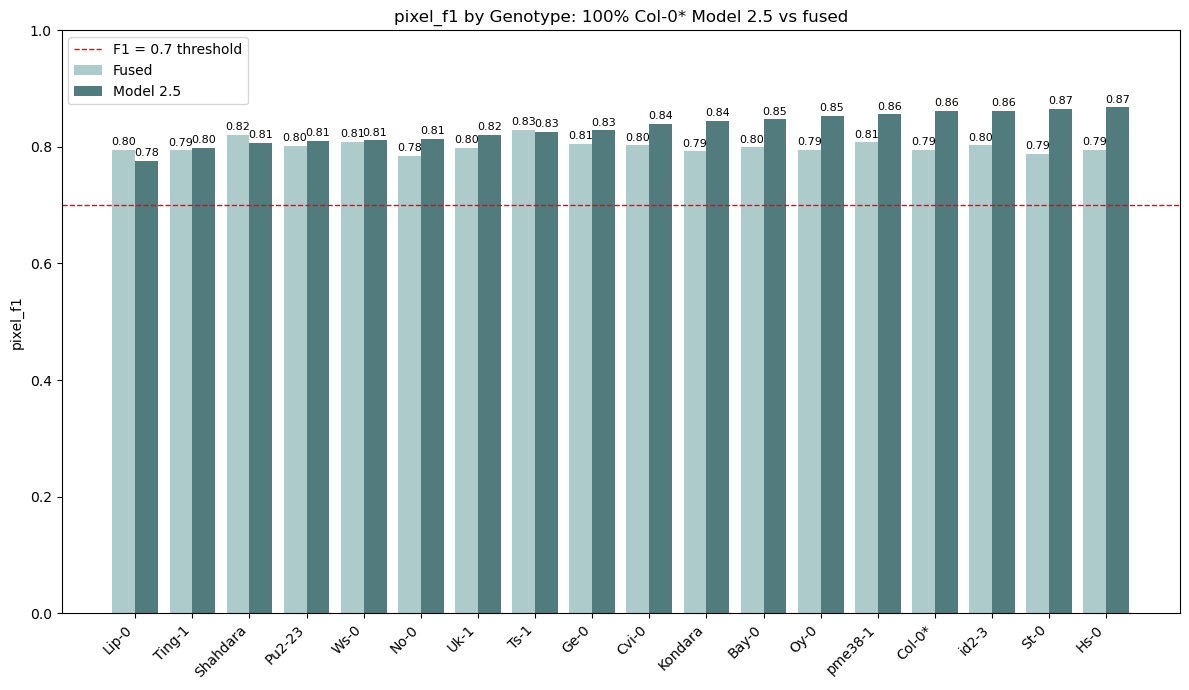

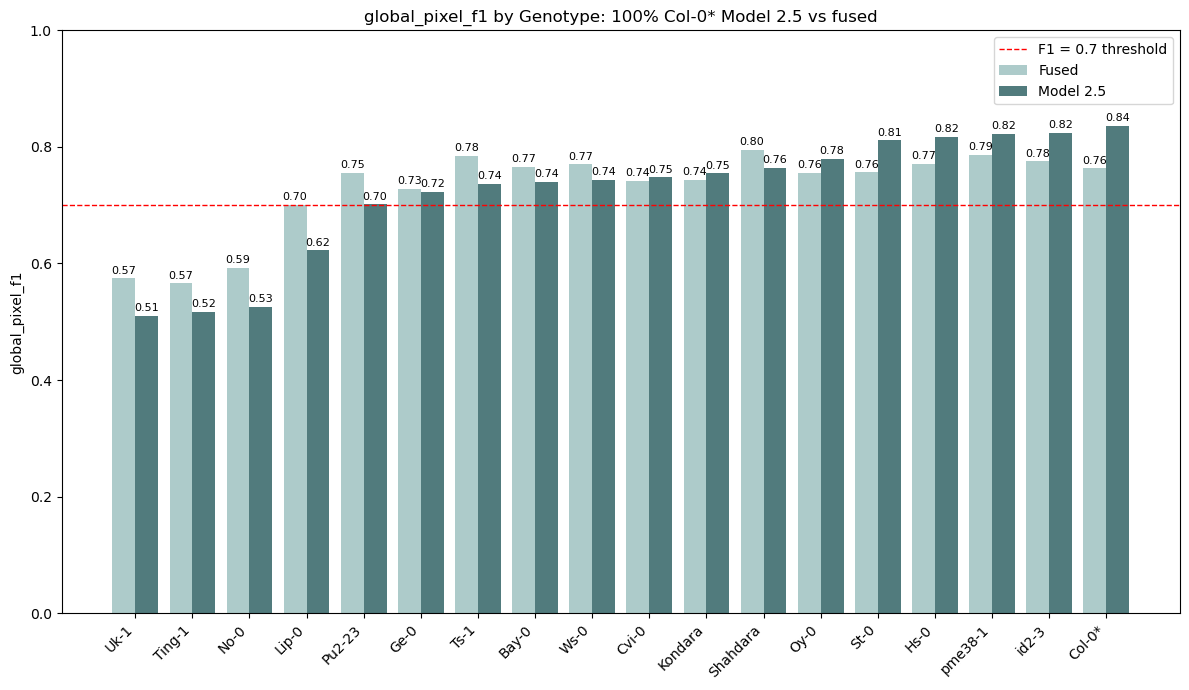

In [38]:



per_genotype_double_plot(fusion_100_no_tangled_data, model_100_no_tangled_data, "instance_f1", "by Genotype: 100% Col-0* Model 2.5 vs fused")
per_genotype_double_plot(fusion_100_no_tangled_data, model_100_no_tangled_data, "pixel_f1", "by Genotype: 100% Col-0* Model 2.5 vs fused")
per_genotype_double_plot(fusion_100_no_tangled_data, model_100_no_tangled_data, "global_pixel_f1", "by Genotype: 100% Col-0* Model 2.5 vs fused")

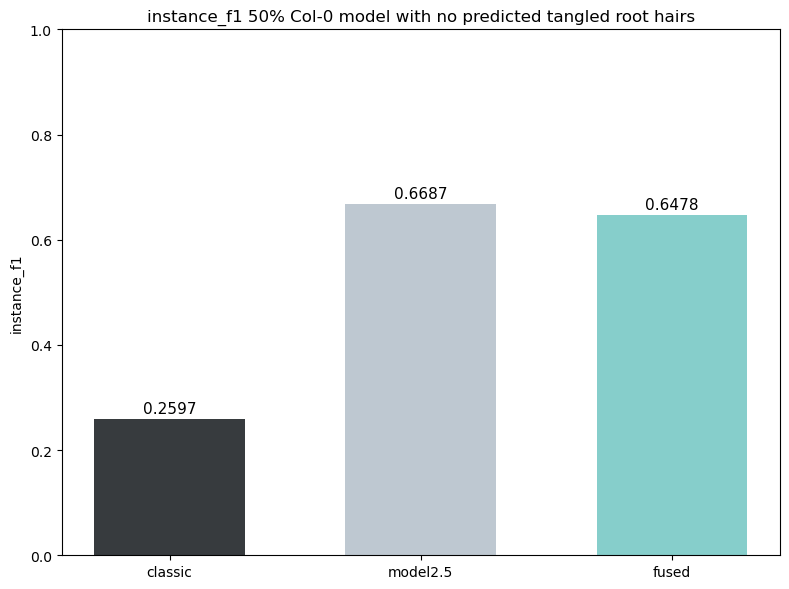

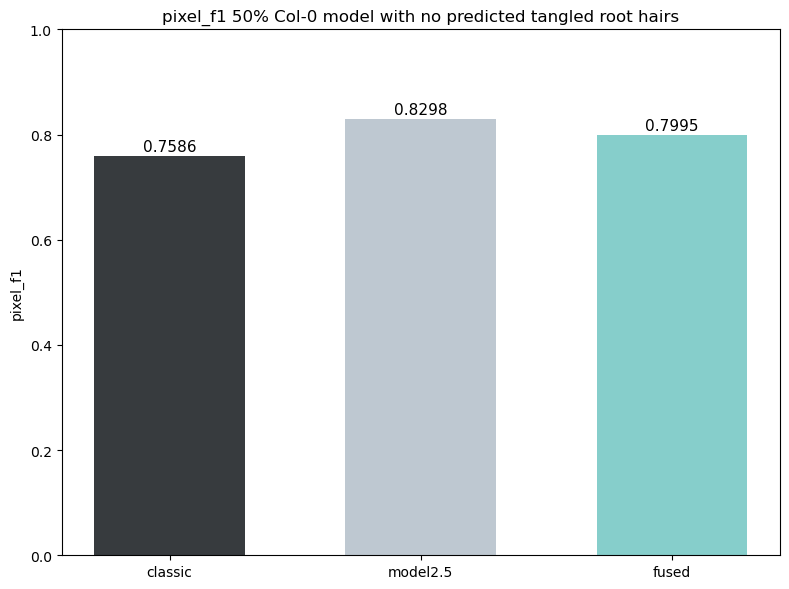

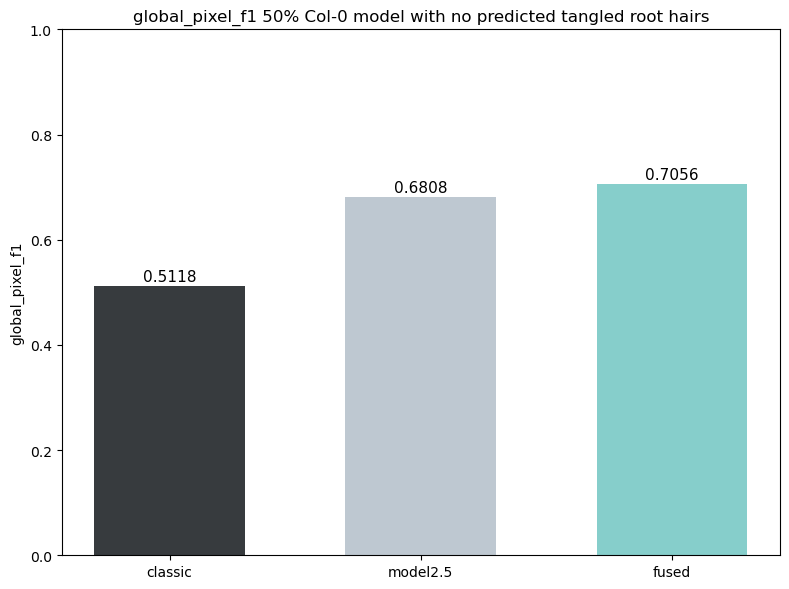

In [39]:

classic_50_no_tangled = f"{folder}/classic_50%_no_tangles.csv"
model_50_no_tangled = f"{folder}/model_50%_no_tangles.csv"
fusion_50_no_tangled = f"{folder}/fusion_50%_no_tangles.csv"

classic_50_no_tangled_data = pd.read_csv(classic_50_no_tangled)
model_50_no_tangled_data = pd.read_csv(model_50_no_tangled)
fusion_50_no_tangled_data = pd.read_csv(fusion_50_no_tangled)

title = "50% Col-0 model with no predicted tangled root hairs"

# Pull TOTAL row from each
classic = classic_50_no_tangled_data[classic_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
model = model_50_no_tangled_data[model_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
fused = fusion_50_no_tangled_data[fusion_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]



overall_plot("instance_f1", classic, model, fused, title)
overall_plot("pixel_f1", classic, model, fused, title)
overall_plot("global_pixel_f1", classic, model, fused, title)


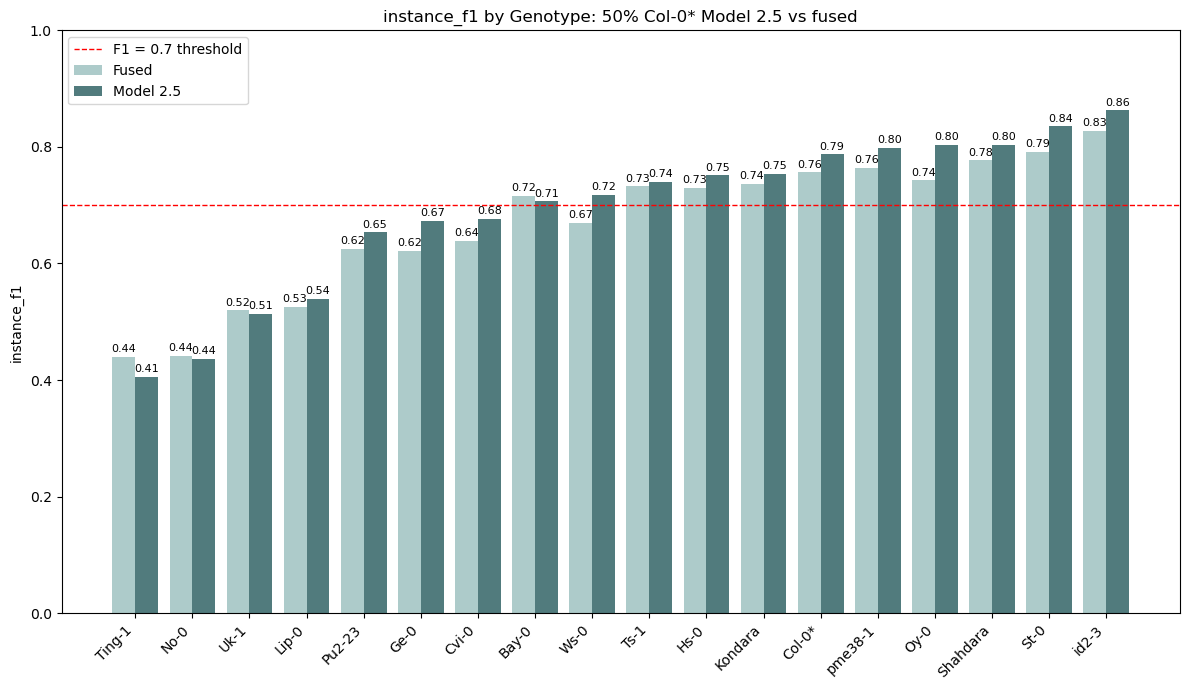

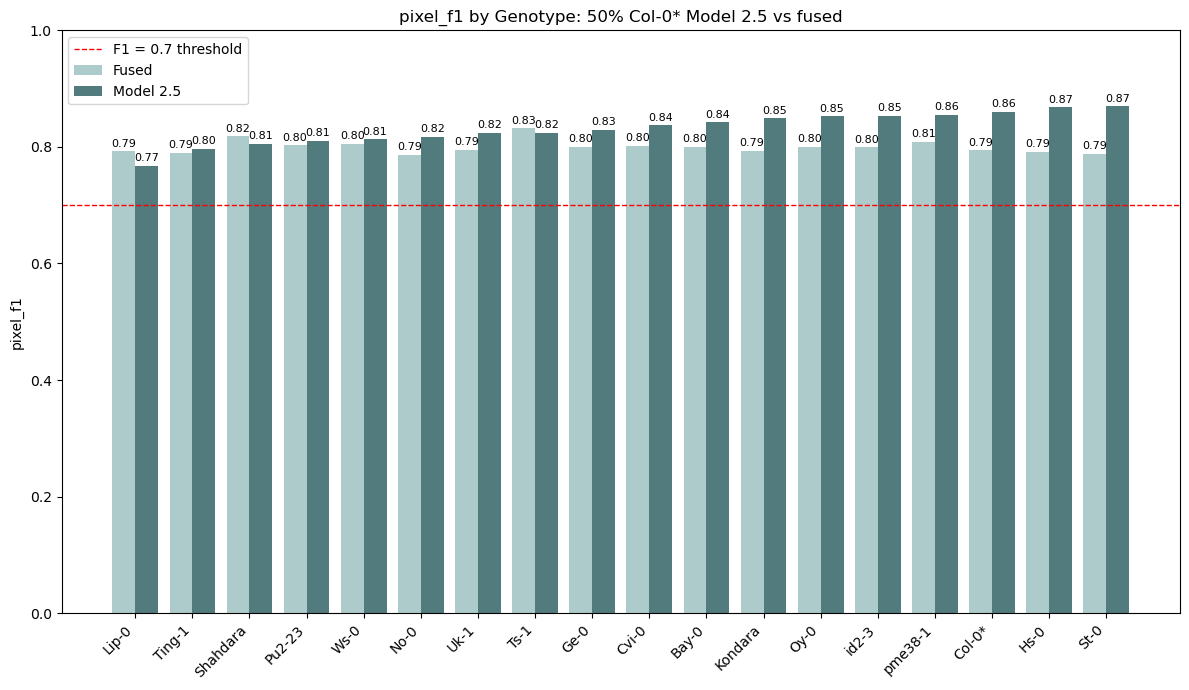

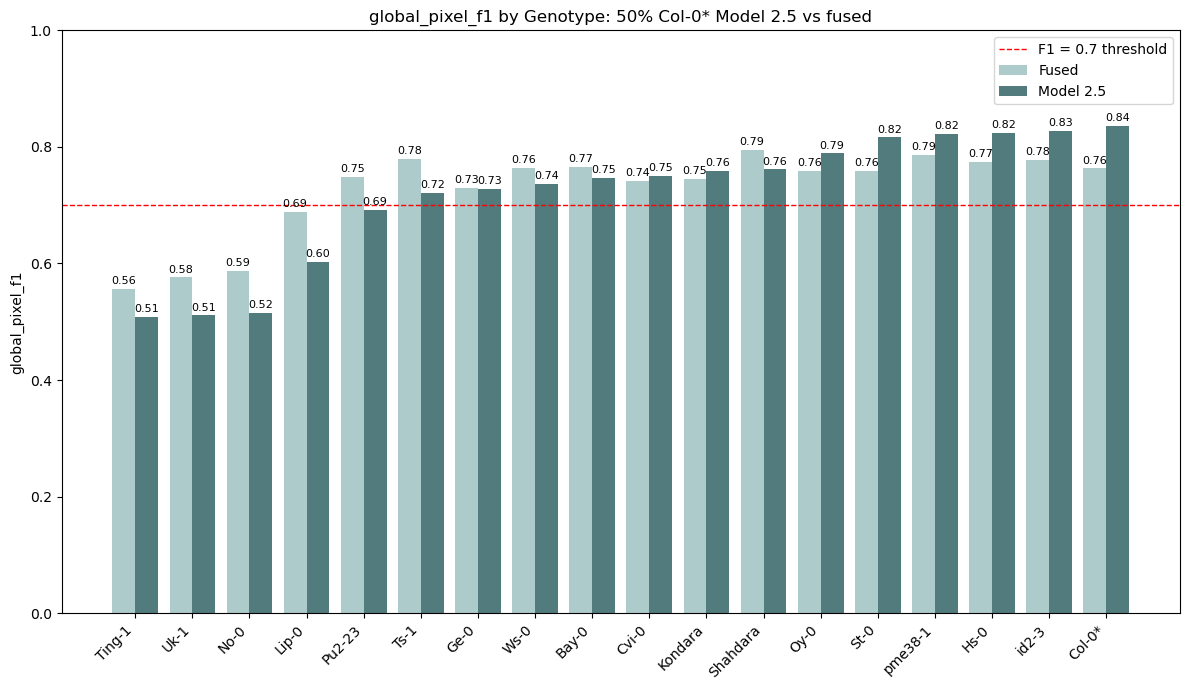

In [40]:
per_genotype_double_plot(fusion_50_no_tangled_data, model_50_no_tangled_data, "instance_f1", "by Genotype: 50% Col-0* Model 2.5 vs fused")
per_genotype_double_plot(fusion_50_no_tangled_data, model_50_no_tangled_data, "pixel_f1", "by Genotype: 50% Col-0* Model 2.5 vs fused")
per_genotype_double_plot(fusion_50_no_tangled_data, model_50_no_tangled_data, "global_pixel_f1", "by Genotype: 50% Col-0* Model 2.5 vs fused")

# 50 vs 100 (no tangled)

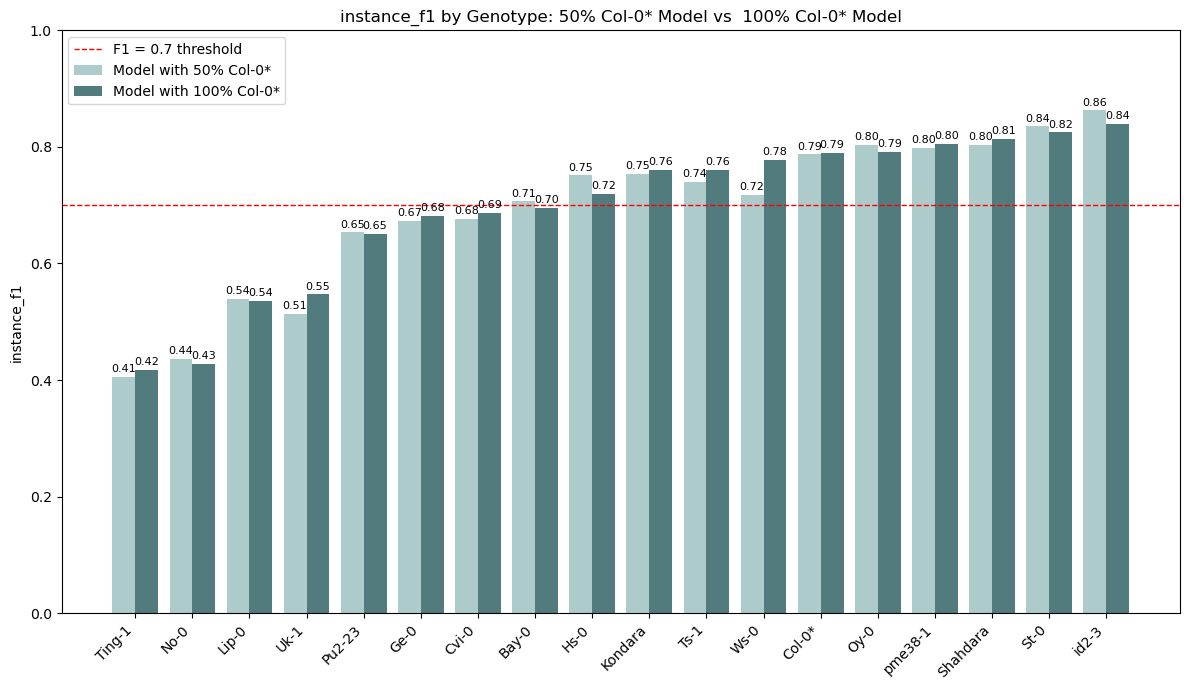

In [41]:
per_genotype_double_plot(model_50_no_tangled_data, model_100_no_tangled_data, 
                         "instance_f1", "by Genotype: 50% Col-0* Model vs  100% Col-0* Model", 
                         labels=["Model with 50% Col-0*", "Model with 100% Col-0*"])

# per_genotype_double_plot(fusion_50_no_tangled_data, fusion_100_no_tangled_data, 
#                          "instance_f1", "by Genotype: 50% Col-0* Fused vs  100% Col-0* Fused", 
#                          labels=["Fusion with 50% Col-0*", "Fusion with 100% Col-0*"])


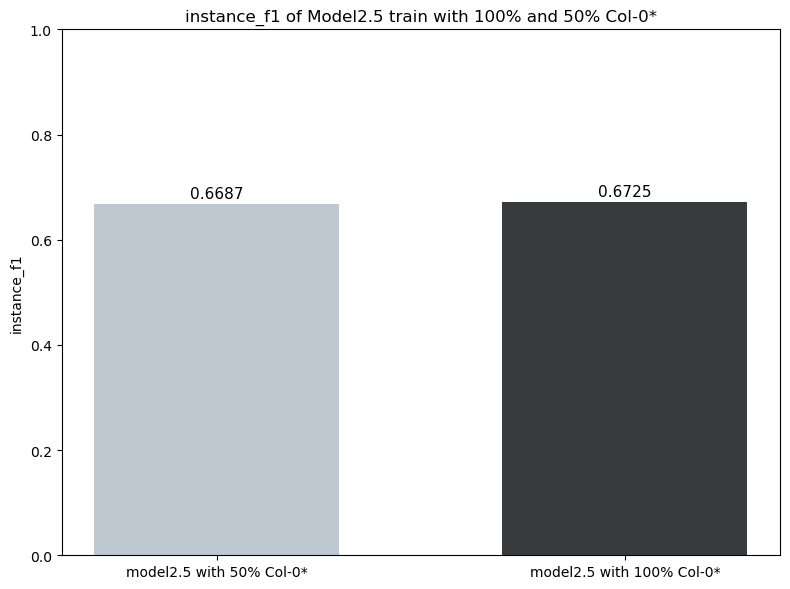

In [42]:
model_100 = model_100_no_tangled_data[model_100_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
model_50 = model_50_no_tangled_data[model_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]

metric = "instance_f1"

pipelines = ["model2.5 with 50% Col-0*", "model2.5 with 100% Col-0*"]
instance_vals = [
    model_50[metric],
    model_100[metric]
]


colours = ["#bec8d1", "#373b3e"]  # coral -> plum gradient

plt.figure(figsize=(8, 6))
bars = plt.bar(pipelines, instance_vals, color=colours, width=0.6)

for bar, val in zip(bars, instance_vals):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.4f}", ha="center", fontsize=11)

plt.ylabel(metric)
plt.title(f"{metric} of Model2.5 train with 100% and 50% Col-0*")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

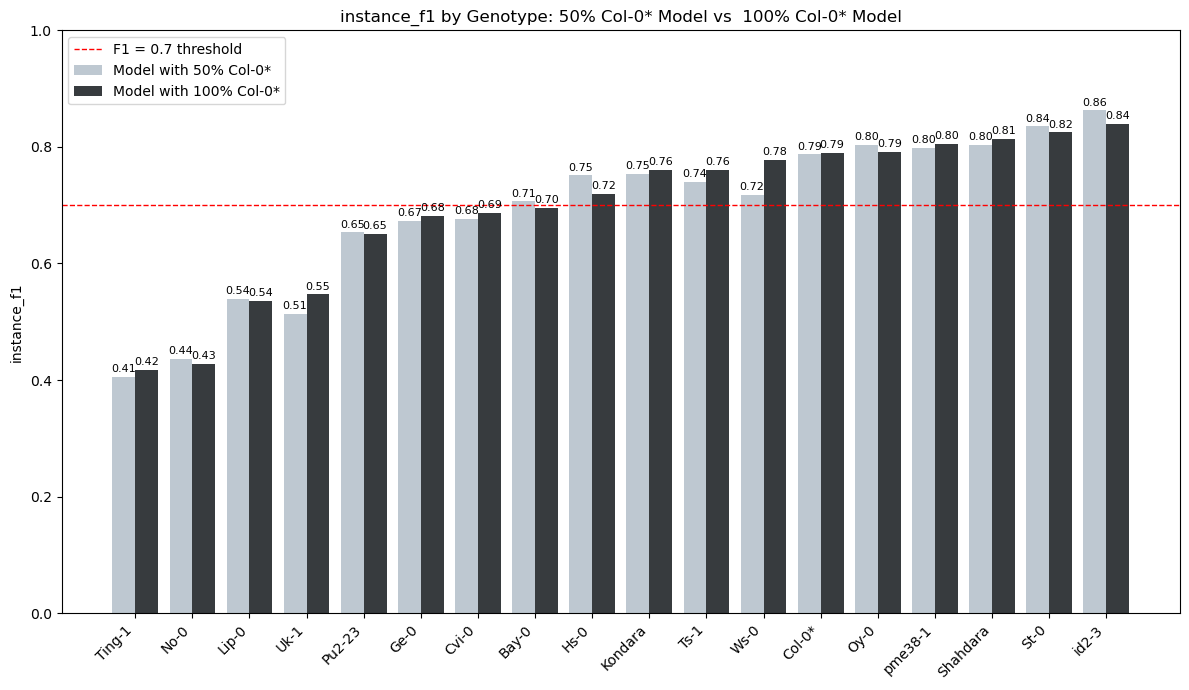

In [43]:
per_genotype_double_plot(model_50_no_tangled_data, model_100_no_tangled_data, 
                         "instance_f1", "by Genotype: 50% Col-0* Model vs  100% Col-0* Model", 
                         labels=["Model with 50% Col-0*", "Model with 100% Col-0*"],
                         colours=colours)

tangled

In [44]:

classic_50_yes_tangled = f"{folder}/classic_50%_yes_tangles.csv"
model_50_yes_tangled = f"{folder}/model_50%_yes_tangles.csv"
fusion_50_yes_tangled = f"{folder}/fusion_50%_yes_tangles.csv"

classic_50_yes_tangled_data = pd.read_csv(classic_50_yes_tangled)
model_50_yes_tangled_data = pd.read_csv(model_50_yes_tangled)
fusion_50_yes_tangled_data = pd.read_csv(fusion_50_yes_tangled)

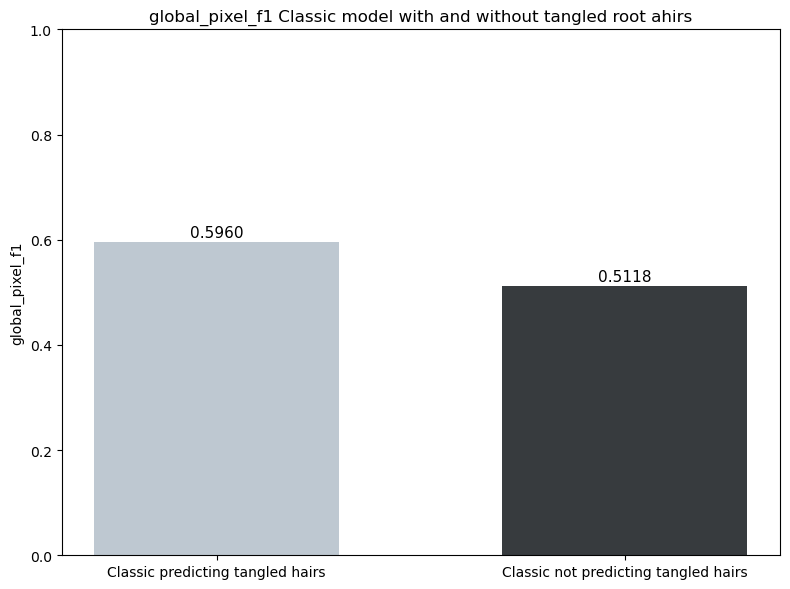

In [45]:
classic_t = classic_50_yes_tangled_data[classic_50_yes_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]
classic_t_not = classic_50_no_tangled_data[classic_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].iloc[0]

metric = "global_pixel_f1"

pipelines = ["Classic predicting tangled hairs", "Classic not predicting tangled hairs"]
instance_vals = [
    classic_t[metric],
    classic_t_not[metric]
]


colours = ["#bec8d1", "#373b3e"]  # coral -> plum gradient

plt.figure(figsize=(8, 6))
bars = plt.bar(pipelines, instance_vals, color=colours, width=0.6)

for bar, val in zip(bars, instance_vals):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.4f}", ha="center", fontsize=11)

plt.ylabel(metric)
plt.title(f"{metric} Classic model with and without tangled root ahirs")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# The megaplot

In [46]:
model_50 = f"{folder}/model_50%_no_tangles.csv"
model_100 = f"{folder}/model_100%_no_tangles.csv"

fusion_100_no_tangled = f"{folder}/fusion_100%_no_tangles.csv"
fusion_100_yes_tangled = f"{folder}/fusion_100%_yes_tangles.csv"

fusion_50_no_tangled = f"{folder}/fusion_50%_no_tangles.csv"
fusion_50_yes_tangled = f"{folder}/fusion_50%_yes_tangles.csv"


model_50_data = pd.read_csv(model_50)
model_100_data = pd.read_csv(model_100)
fusion_100_no_tangled_data = pd.read_csv(fusion_100_no_tangled)
fusion_100_yes_tangled_data = pd.read_csv(fusion_100_yes_tangled)
fusion_50_no_tangled_data = pd.read_csv(fusion_50_no_tangled)
fusion_50_yes_tangled_data = pd.read_csv(fusion_50_yes_tangled)

In [47]:
model_50 = model_50_data[~model_50_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
model_100 = model_100_data[~model_100_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
fusion_100_no_tangled = fusion_100_no_tangled_data[~fusion_100_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
fusion_100_yes_tangled = fusion_100_yes_tangled_data[~fusion_100_yes_tangled_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
fusion_50_no_tangled = fusion_50_no_tangled_data[~fusion_50_no_tangled_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")
fusion_50_yes_tangled = fusion_50_yes_tangled_data[~fusion_50_yes_tangled_data["genotype"].str.contains("TOTAL", case=False)].set_index("genotype")

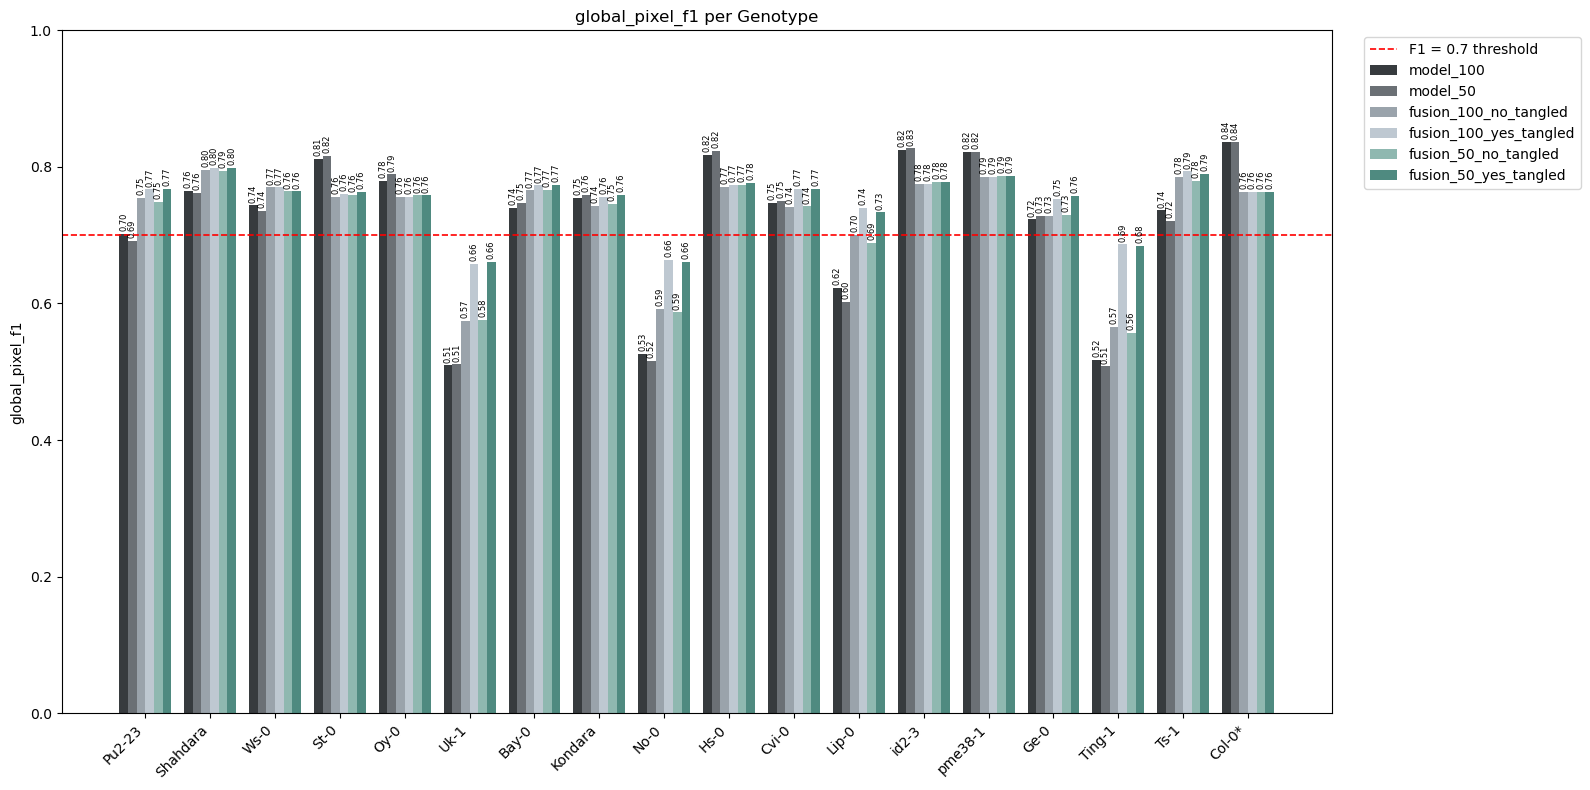

In [48]:
import numpy as np
import matplotlib.pyplot as plt

metric = "global_pixel_f1"

# ordering
GENOTYPES = ["Pu2-23", "Shahdara", "Ws-0", "St-0", "Oy-0", "Uk-1", "Bay-0",
             "Kondara", "No-0", "Hs-0", "Cvi-0", "Lip-0", "id2-3", "pme38-1",
             "Ge-0", "Ting-1", "Ts-1", "Col-0*"]

merged = model_100[[metric]].rename(columns={metric: "model_100"})
merged = merged.join(model_50[[metric]].rename(columns={metric: "model_50"}))
merged = merged.join(fusion_100_no_tangled[[metric]].rename(columns={metric: "fusion_100_no_tangled"}))
merged = merged.join(fusion_100_yes_tangled[[metric]].rename(columns={metric: "fusion_100_yes_tangled"}))
merged = merged.join(fusion_50_no_tangled[[metric]].rename(columns={metric: "fusion_50_no_tangled"}))
merged = merged.join(fusion_50_yes_tangled[[metric]].rename(columns={metric: "fusion_50_yes_tangled"}))

# merged = merged.sort_values("fusion_100_no_tangled", ascending=True)
merged = merged.reindex(GENOTYPES)

genotype_order = merged.index.tolist()
pipeline_names = ["model_100", "model_50", "fusion_100_no_tangled",
                   "fusion_100_yes_tangled", "fusion_50_no_tangled", "fusion_50_yes_tangled"]
colours = ["#373b3e", "#6b7075", "#9aa3ab", "#bec8d1", "#8fb8b0", "#4f8a80"]

n_pipelines = len(pipeline_names)
x = np.arange(len(merged))
width = 0.8 / n_pipelines

plt.figure(figsize=(16, 8))

for i, (pipeline, colour) in enumerate(zip(pipeline_names, colours)):
    offset = (i - (n_pipelines - 1) / 2) * width
    bars = plt.bar(x + offset, merged[pipeline], width=width, color=colour, label=pipeline)
    plt.bar_label(bars, fmt="%.2f", fontsize=6, rotation=90, padding=2)

plt.axhline(y=0.7, color="red", linestyle="--", linewidth=1.2, label="F1 = 0.7 threshold")

plt.xticks(x, genotype_order, rotation=45, ha="right")
plt.ylabel(metric)
plt.title(f"{metric} per Genotype")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

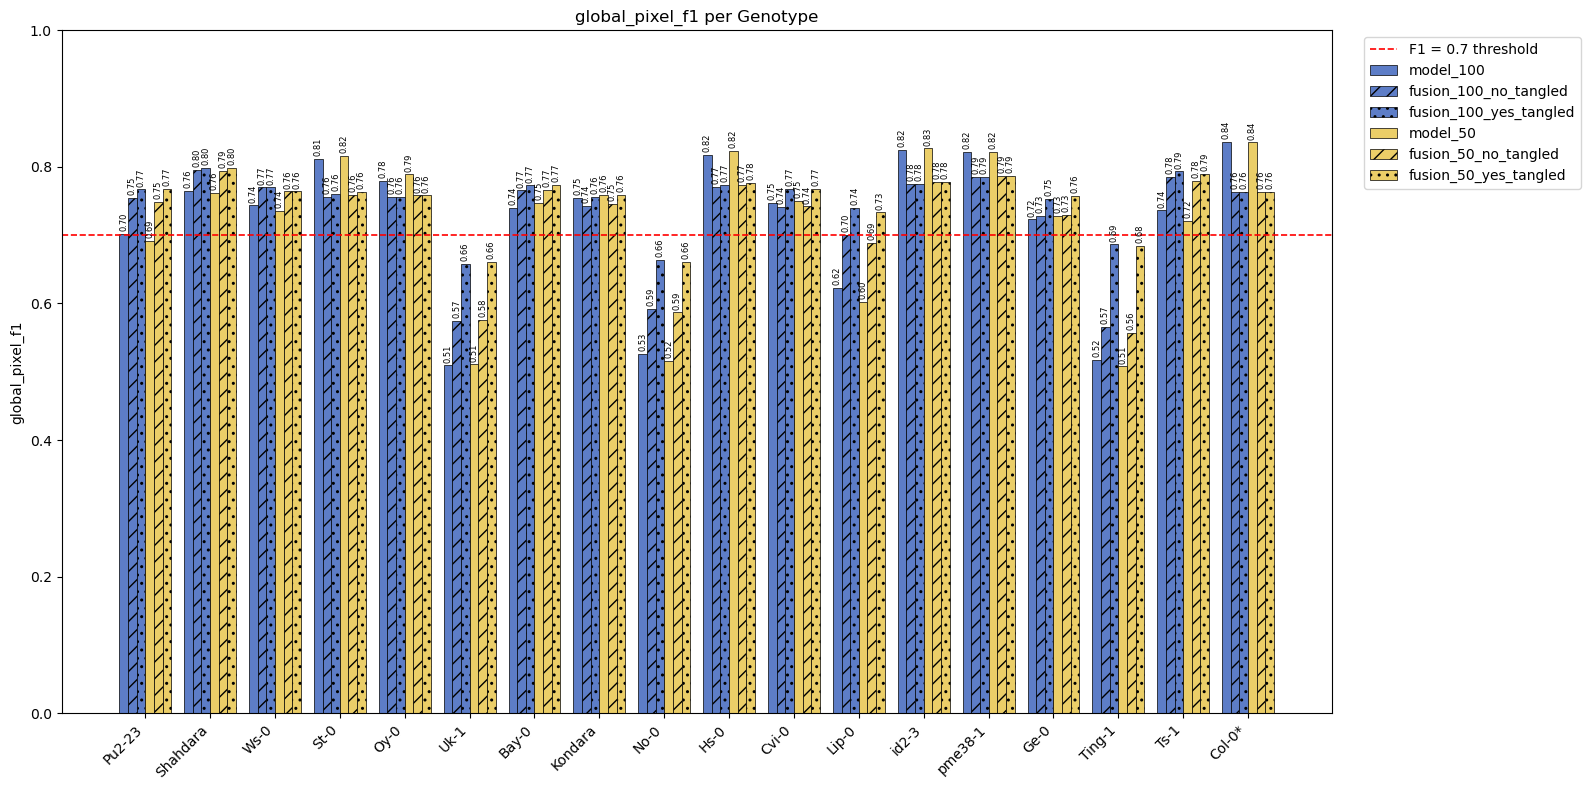

In [49]:
import numpy as np
import matplotlib.pyplot as plt

metric = "global_pixel_f1"

GENOTYPES = ["Pu2-23", "Shahdara", "Ws-0", "St-0", "Oy-0", "Uk-1", "Bay-0",
             "Kondara", "No-0", "Hs-0", "Cvi-0", "Lip-0", "id2-3", "pme38-1",
             "Ge-0", "Ting-1", "Ts-1", "Col-0*"]

merged = model_100[[metric]].rename(columns={metric: "model_100"})
merged = merged.join(fusion_100_no_tangled[[metric]].rename(columns={metric: "fusion_100_no_tangled"}))
merged = merged.join(fusion_100_yes_tangled[[metric]].rename(columns={metric: "fusion_100_yes_tangled"}))
merged = merged.join(model_50[[metric]].rename(columns={metric: "model_50"}))
merged = merged.join(fusion_50_no_tangled[[metric]].rename(columns={metric: "fusion_50_no_tangled"}))
merged = merged.join(fusion_50_yes_tangled[[metric]].rename(columns={metric: "fusion_50_yes_tangled"}))

merged = merged.reindex(GENOTYPES)

genotype_order = merged.index.tolist()

# reordered to match the hatch grouping: no_tangled pair first, then yes_tangled pair
pipeline_names = ["model_100", "fusion_100_no_tangled", "fusion_100_yes_tangled", 
                 "model_50", "fusion_50_no_tangled", "fusion_50_yes_tangled"]

colours = [
    "#5D7DC7",   # model_100 -- flat dark gray
    "#5D7DC7",   # fusion_100_no_tangled -- deep cornflower
    "#5D7DC7",   # fusion_100_yes_tangled -- deep gold
    "#EBCE68",    # model_50  -- flat mid gray
    "#EBCE68",    # fusion_50_no_tangled  -- mid cornflower
    "#EBCE68",   # fusion_50_yes_tangled  -- pale gold
]

hatches = [
    None,   # model_100 -- flat, no hatch
    "//",   # fusion_100_no_tangled -- dot pattern
    "..",   # fusion_100_yes_tangled -- diagonal stripes
    None,   # model_50 -- flat, no hatch
    "//",   # fusion_50_no_tangled -- dot pattern
    "..",   # fusion_50_yes_tangled -- diagonal stripes
]

n_pipelines = len(pipeline_names)
x = np.arange(len(merged))
width = 0.8 / n_pipelines

plt.figure(figsize=(16, 8))

for i, (pipeline, colour, hatch) in enumerate(zip(pipeline_names, colours, hatches)):
    offset = (i - (n_pipelines - 1) / 2) * width
    bars = plt.bar(x + offset, merged[pipeline], width=width, color=colour,
                    hatch=hatch, edgecolor="black", linewidth=0.5, label=pipeline)
    plt.bar_label(bars, fmt="%.2f", fontsize=6, rotation=90, padding=2)

plt.axhline(y=0.7, color="red", linestyle="--", linewidth=1.2, label="F1 = 0.7 threshold")

plt.xticks(x, genotype_order, rotation=45, ha="right")
plt.ylabel(metric)
plt.title(f"{metric} per Genotype")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{metric}.svg")
plt.show()

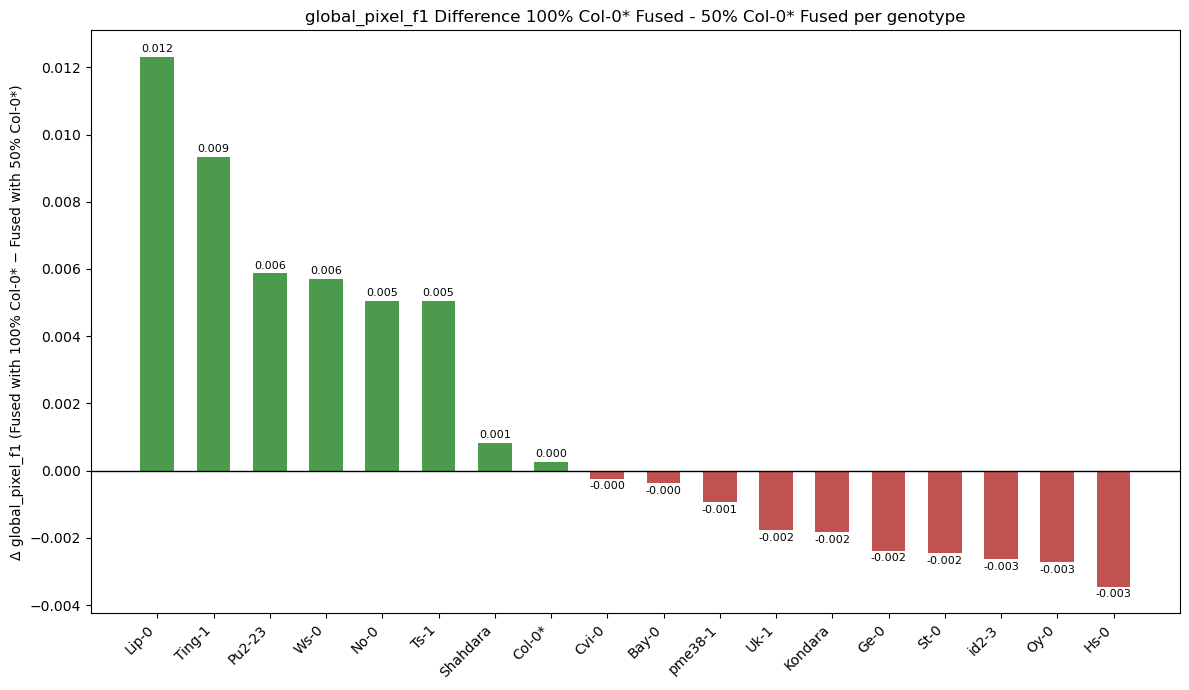

In [50]:
# per_genotype_double_plot(fusion_50_no_tangled_dat

per_genotype_diff_plot(fusion_100_no_tangled_data, fusion_50_no_tangled_data, metric="global_pixel_f1", 
                    title="100% Col-0* Fused - 50% Col-0* Fused per genotype", labels=["Fused with 50% Col-0*", "Fused with 100% Col-0*"])

In [51]:
import json
import cv2
from collections import defaultdict

ground_truth_images = "/home/mellanie/Desktop/Tristan_2026_code/detectron2/model2.5_data/test.json"
fused_predictions = "/home/mellanie/Desktop/Tristan_2026_code/outputs/fusion_output_50%_col0_no_tangles.json"

with open(ground_truth_images) as f:
    gt_data = json.load(f)

with open(fused_predictions) as p:
    predictions = json.load(p)

# ground truth: filename -> ecotype metadata
image_meta_by_filename = {
    img["file_name"]: {
        "gt_image_id": img["id"],
        "height": img["height"],
        "width": img["width"],
        "ecotype": img.get("ecotype", img["file_name"]),
    } for img in gt_data["images"]
}

# predictions file has its OWN, separately-assigned image_id space --
# build this mapping from predictions["images"], NOT from gt_data
pred_id_to_filename = {img["id"]: img["file_name"] for img in predictions["images"]}



high_instances = ["St-0",
                "Hs-0",
                "Cvi-0",
                "Kondara",
                "Oy-0",
                "pme38-1"]

low_instances = ["Pu2-23",
                "Uk-1",
                "No-0",
                "Lip-0",
                "Ge-0",
                "Ting-1"]

instances = ["Uk-1"]


# group predictions by filename (using the PREDICTIONS file's own id->filename map)
annotations_by_filename = defaultdict(list)
for item in predictions["annotations"]:
    filename = pred_id_to_filename[item["image_id"]]  # <-- was id_to_filename (from gt) before, now fixed
    annotations_by_filename[filename].append(item)

# now match up with ecotype using filename as the shared key across both files
for filename, anns in annotations_by_filename.items():
    if filename not in image_meta_by_filename:
        print(f"WARNING: {filename} not found in ground truth metadata -- skipping")
        continue

    ecotype = image_meta_by_filename[filename]["ecotype"]

    if ecotype in instances:
        print(f"{filename}  ({ecotype})  —  {len(anns)} predicted instances")

/home/mellanie/Desktop/Annotated_dataset/20240925_N4_Plate1_DAG6_1000_L/000009.tif  (Uk-1)  —  62 predicted instances
/home/mellanie/Desktop/Annotated_dataset/20240925_N4_Plate1_DAG6_1000_L/000008.tif  (Uk-1)  —  41 predicted instances
/home/mellanie/Desktop/Annotated_dataset/20240925_N4_Plate1_DAG6_1000_L/000007.tif  (Uk-1)  —  64 predicted instances


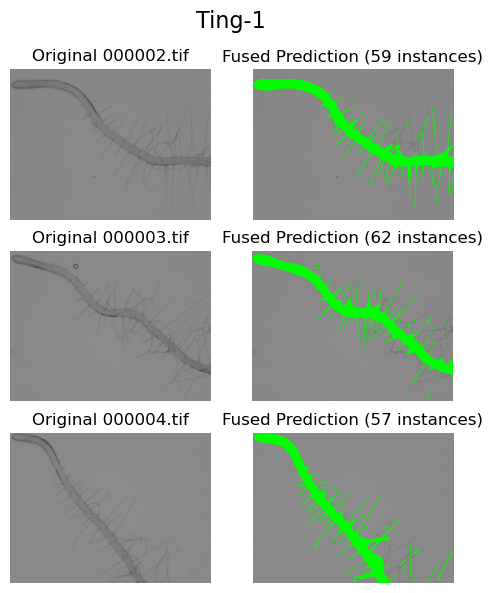

In [52]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

target_genotype = "Ting-1"

# get just the filenames belonging to this one genotype
genotype_filenames = [
    fname for fname in annotations_by_filename
    if image_meta_by_filename.get(fname, {}).get("ecotype") == target_genotype
]

if len(genotype_filenames) != 3:
    print(f"WARNING: expected 3 images for {target_genotype}, found {len(genotype_filenames)}")

fig, axes = plt.subplots(3, 2, figsize=(5, 6))

for row, filename in enumerate(genotype_filenames):
    img = cv2.imread(filename)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- Column 1: original image ---
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].axis("off")
    axes[row, 0].set_title(f"Original {filename.split('/')[-1]}")

    # --- Column 2: fused prediction overlay ---
    overlay = img_rgb.copy()
    anns = annotations_by_filename[filename]

    for ann in anns:
        rle = ann["segmentation"]
        decoded_mask = mask_utils.decode(rle).astype(bool)
        overlay[decoded_mask] = [0, 255, 0]

    axes[row, 1].imshow(overlay)
    axes[row, 1].axis("off")
    axes[row, 1].set_title(f"Fused Prediction ({len(anns)} instances)")

fig.suptitle(f"{target_genotype}", fontsize=16)
plt.tight_layout()
plt.show()

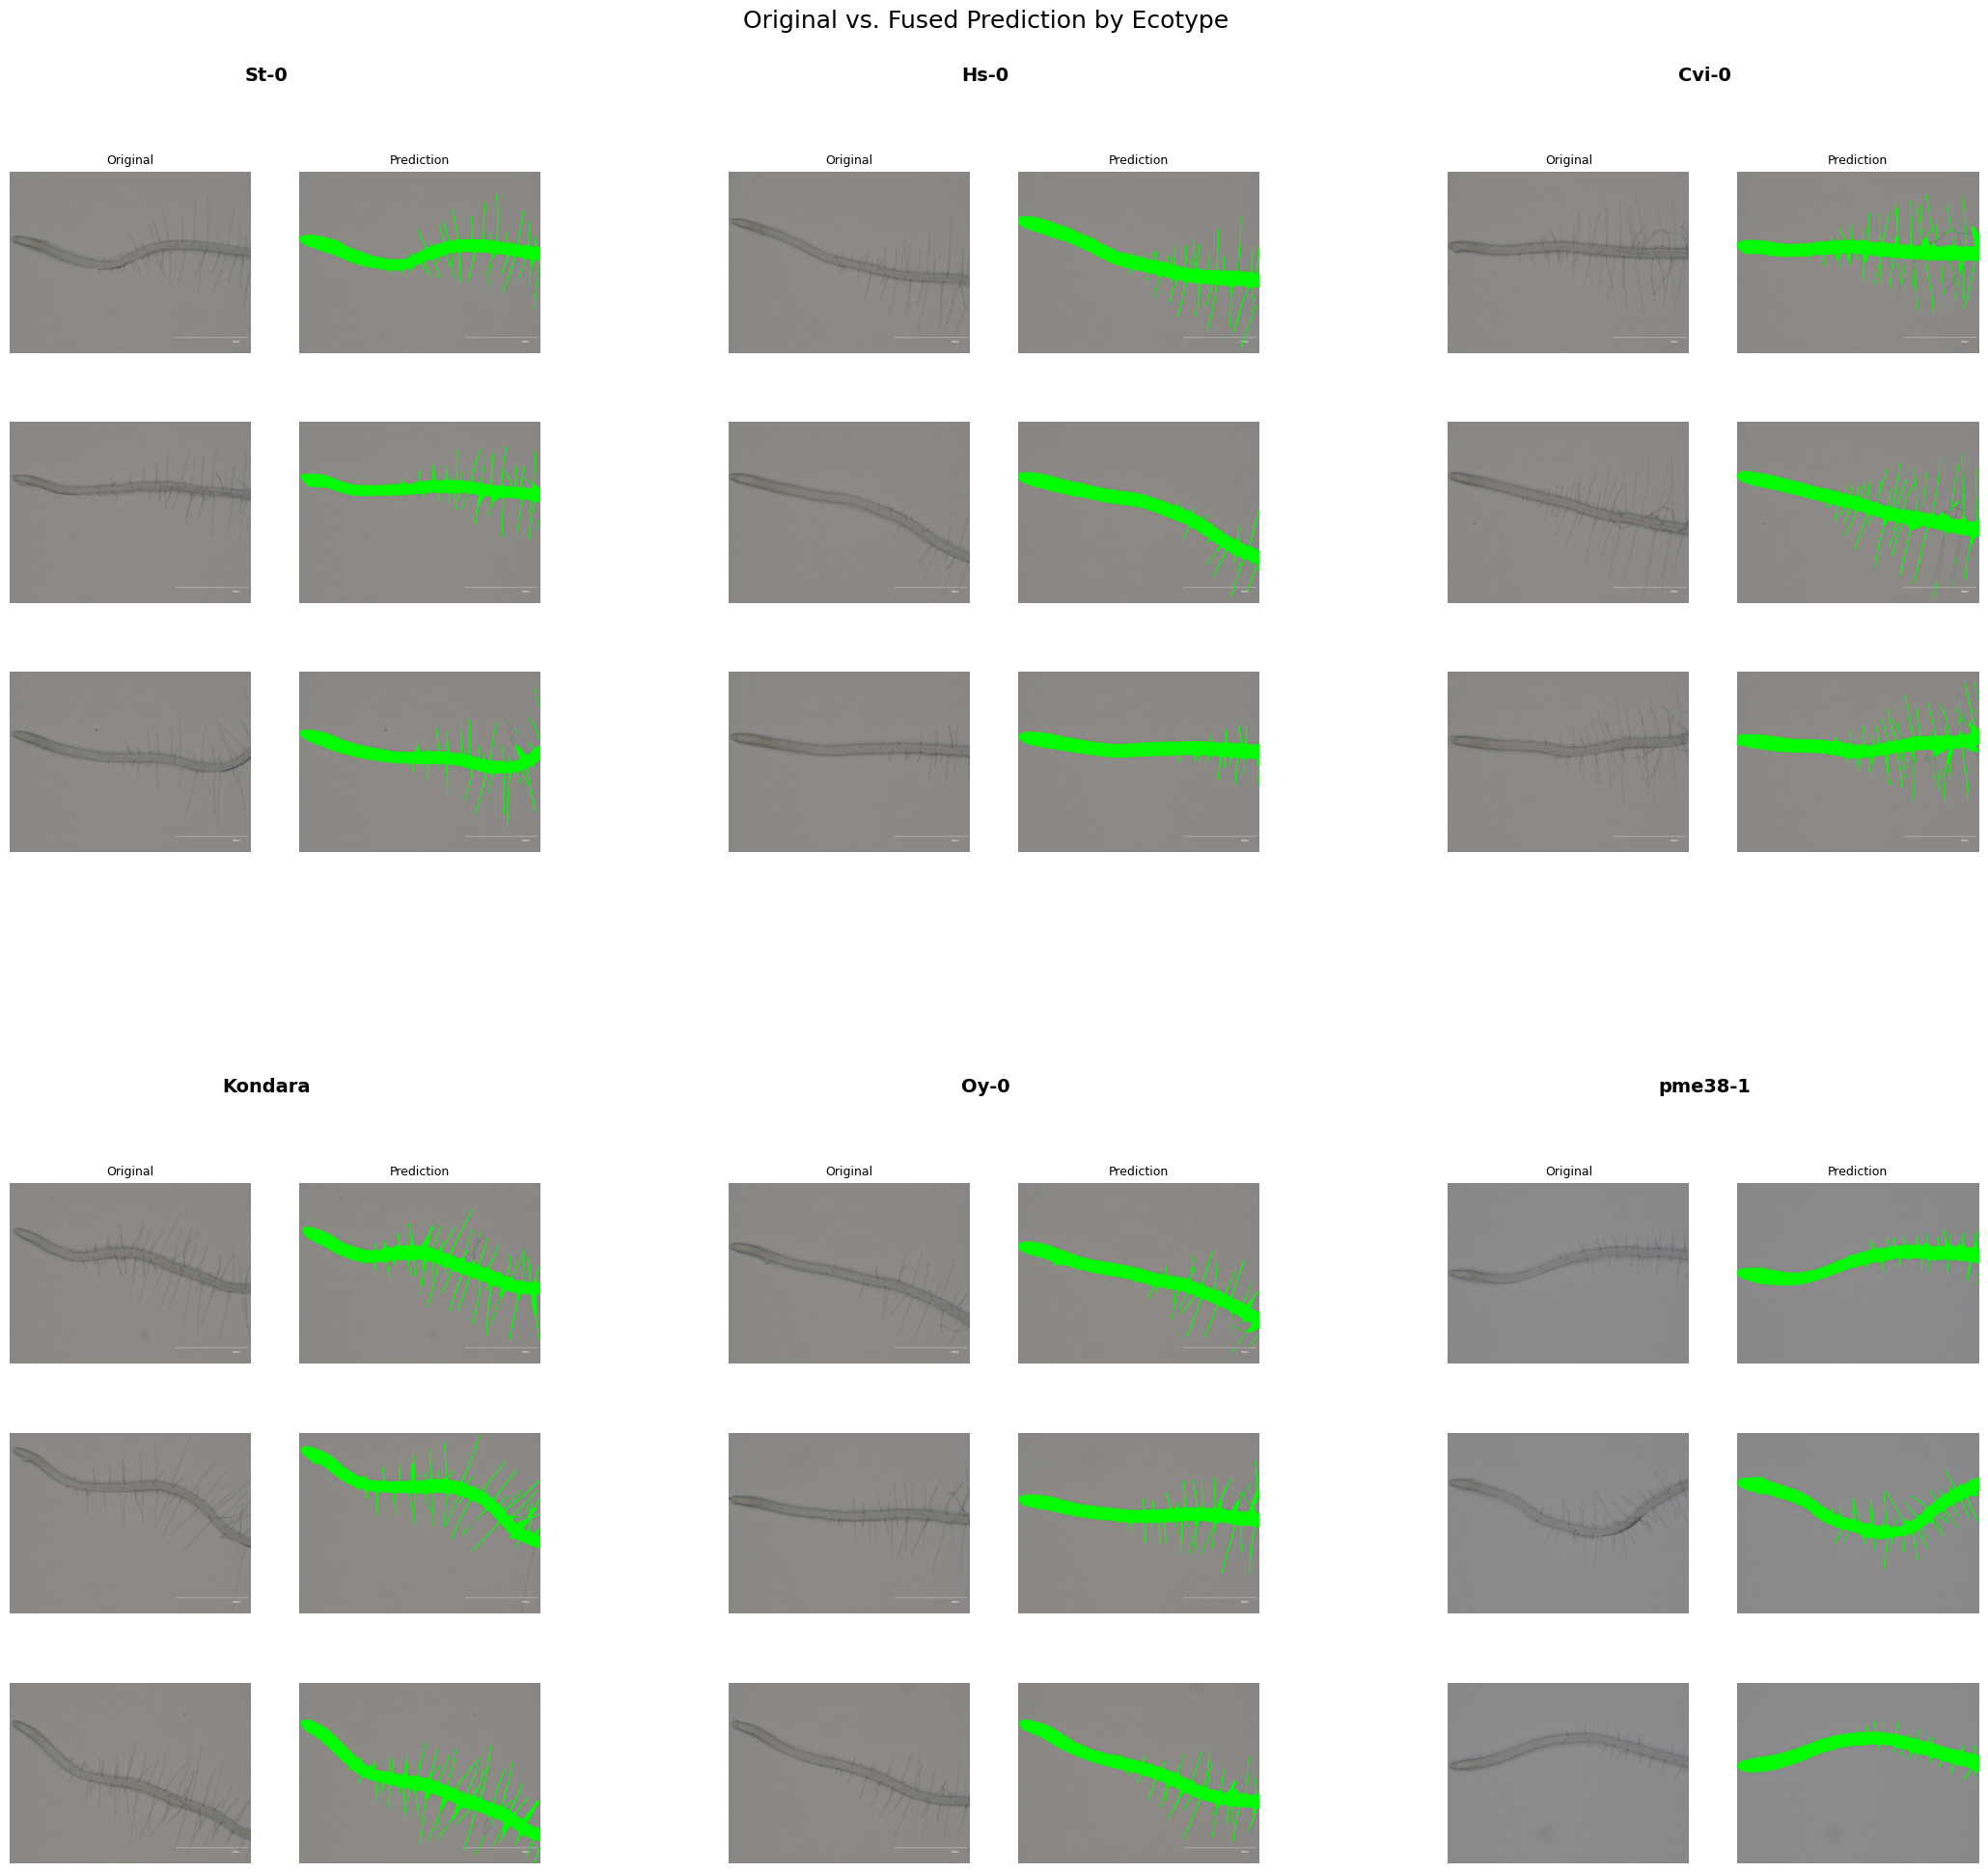

In [53]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

target_ecotypes = high_instances

# outer figure: 2 rows x 3 columns of subfigures, one per ecotype
fig = plt.figure(figsize=(22, 20))
subfigs = fig.subfigures(2, 3, wspace=0.05, hspace=0.1)
subfigs_flat = subfigs.flatten()

for panel_idx, ecotype in enumerate(target_ecotypes):
    subfig = subfigs_flat[panel_idx]
    subfig.suptitle(ecotype, fontsize=14, fontweight="bold")

    # inner grid for this ecotype: 3 rows (images) x 2 columns (original / prediction)
    axes = subfig.subplots(3, 2)

    genotype_filenames = [
        fname for fname in annotations_by_filename
        if image_meta_by_filename.get(fname, {}).get("ecotype") == ecotype
    ]

    if len(genotype_filenames) != 3:
        print(f"WARNING: expected 3 images for {ecotype}, found {len(genotype_filenames)}")

    for row, filename in enumerate(genotype_filenames):
        img = cv2.imread(filename)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # --- Column 1: original ---
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].axis("off")
        if row == 0:
            axes[row, 0].set_title("Original", fontsize=9)

        # --- Column 2: fused prediction overlay ---
        overlay = img_rgb.copy()
        anns = annotations_by_filename[filename]

        for ann in anns:
            rle = ann["segmentation"]
            decoded_mask = mask_utils.decode(rle).astype(bool)
            overlay[decoded_mask] = [0, 255, 0]

        axes[row, 1].imshow(overlay)
        axes[row, 1].axis("off")
        if row == 0:
            axes[row, 1].set_title(f"Prediction", fontsize=9)

fig.suptitle("Original vs. Fused Prediction by Ecotype", fontsize=18, y=1.02)
plt.savefig("ecotype_grid_comparison.png", dpi=150, bbox_inches="tight")
plt.show()